# CodeAlpha Data Science Virtual Internship
## Task 2: Unemployment Analysis with Python

**Author:** Data Science Intern  
**Repository:** `CodeAlpha_Unemployment_Analysis`  
**Domain:** Data Science & Exploratory Data Analysis (EDA)  

---

### Project Objective
The objective of this project is to perform an in-depth exploratory data analysis on the unemployment rate in India across different states and geographic sectors (Rural vs Urban). We examine temporal trends from May 2019 through June 2020, quantify the labor market impact during the COVID-19 pandemic and subsequent nationwide lockdowns, identify regional disparities, and outline policy-relevant insights.

### 1. Environment Setup & Library Imports

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure local src modules can be imported
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_loader import load_raw_data
from src.preprocessing import preprocess_unemployment_data
from src.analysis import (
    calculate_summary_statistics,
    analyze_trends_over_time,
    analyze_regional_differences,
    analyze_area_differences,
    analyze_covid_impact,
    generate_key_findings
)
from src.visualization import (
    plot_unemployment_trend,
    plot_regional_comparison,
    plot_distribution,
    plot_area_boxplot,
    plot_covid_comparison,
    plot_monthly_heatmap
)

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid')
print("All libraries imported successfully.")

All libraries imported successfully.


### 2. Dataset Loading & Initial Inspection
We load the raw dataset from `data/unemployment.csv` and inspect the initial structure, shape, columns, and data types.

In [2]:
raw_df = load_raw_data("unemployment.csv")
print("Raw shape:", raw_df.shape)
raw_df.head()

[INFO] Loading raw dataset from: unemployment.csv
[INFO] Successfully loaded 768 rows and 7 columns.
Raw shape: (768, 7)


In [3]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


### 3. Data Cleaning & Preprocessing
Key data cleaning steps implemented:
1. **Header whitespace cleanup**: The raw column names contain leading spaces (e.g. `' Date'`, `' Estimated Unemployment Rate (%)'`).
2. **Null row handling**: 28 completely blank records exist at the end of the survey file; these are safely dropped.
3. **String strip**: Whitespace trimmed from categorical columns (`Region`, `Area`, `Frequency`).
4. **Datetime conversion**: Converted `Date` to `datetime64[ns]` with dayfirst parsing.
5. **Feature engineering**: Extracted `Year`, `Month`, `Month_Name`, and established analytical groups for `COVID_Period` (`Pre-COVID` vs `COVID-19 Period`).

In [4]:
df = preprocess_unemployment_data(raw_df, save_cleaned=True)
print("Cleaned DataFrame Shape:", df.shape)
df.head()


--- Starting Data Preprocessing ---
[INFO] Cleaned columns: ['Region', 'Date', 'Frequency', 'Estimated_Unemployment_Rate_Pct', 'Estimated_Employed', 'Estimated_Labour_Participation_Rate_Pct', 'Area']
[INFO] Missing values before cleaning:
Region                                     28
Date                                       28
Frequency                                  28
Estimated_Unemployment_Rate_Pct            28
Estimated_Employed                         28
Estimated_Labour_Participation_Rate_Pct    28
Area                                       28
dtype: int64
[INFO] Dropped 28 completely empty rows.
[INFO] No duplicate rows detected.
[INFO] Date range: 2019-05-31 to 2020-06-30
[INFO] Cleaned dataset saved to: outputs/cleaned_unemployment_data.csv
[INFO] Preprocessing complete. Final shape: (740, 11)
Cleaned DataFrame Shape: (740, 11)


### 4. Descriptive Summary Statistics

In [5]:
summary_stats = calculate_summary_statistics(df)
summary_stats

           Estimated_Unemployment_Rate_Pct  Estimated_Employed  Estimated_Labour_Participation_Rate_Pct
Count                               740.00              740.00                                   740.00
Mean                                 11.79          7204460.03                                    42.63
Std_Dev                              10.72          8087988.43                                     8.11
Median                                8.35          4744178.50                                    41.16
Min                                   0.00            49420.00                                    13.33
Q25 (25%)                             4.66          1190404.50                                    38.06
Q75 (75%)                            15.89         11275489.50                                    45.50
IQR                                  11.23         10085085.00                                     7.44
Max                                  76.74         45777509.00  

### 5. Unemployment Trends Over Time
Tracking national monthly average unemployment rates across India.

In [ ]:
trend_df = analyze_trends_over_time(df)
trend_df

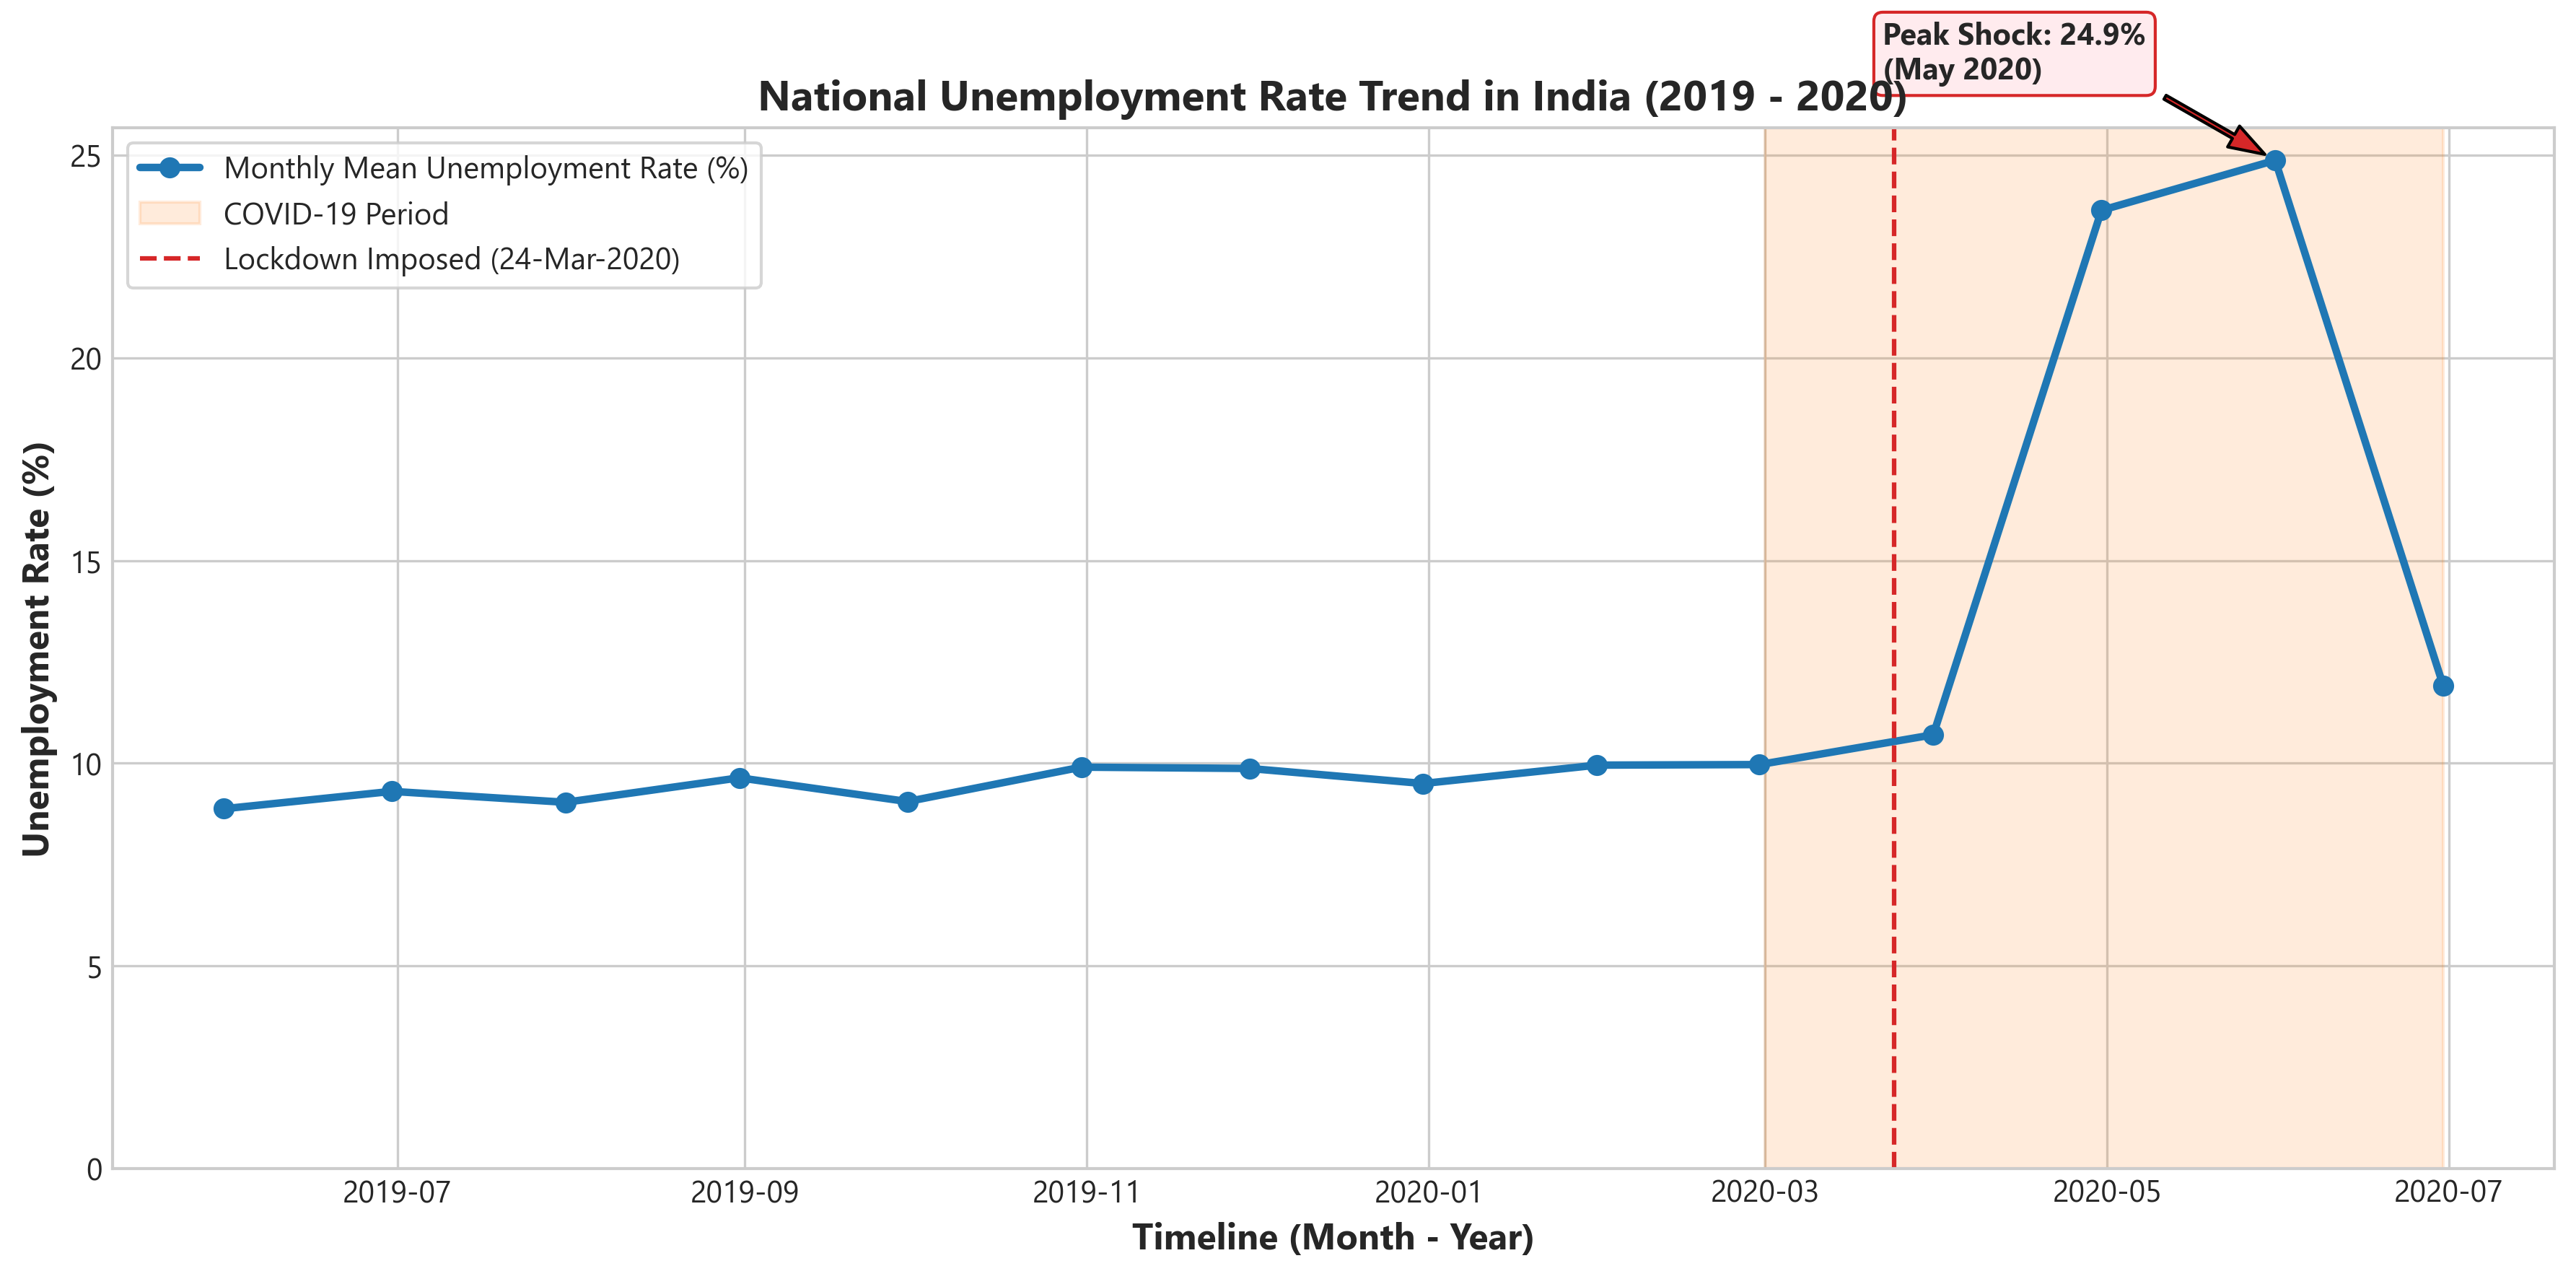

In [6]:
fig1 = plot_unemployment_trend(df, save=True)
plt.show()

### 6. State-Level Disparities
Comparing average unemployment rates across all Indian states and Union Territories.

In [ ]:
state_summary, top_5, low_5 = analyze_regional_differences(df)
print("--- Top 5 States with Highest Average Unemployment ---")
display(top_5)

print("\n--- Top 5 States with Lowest Average Unemployment ---")
display(low_5)

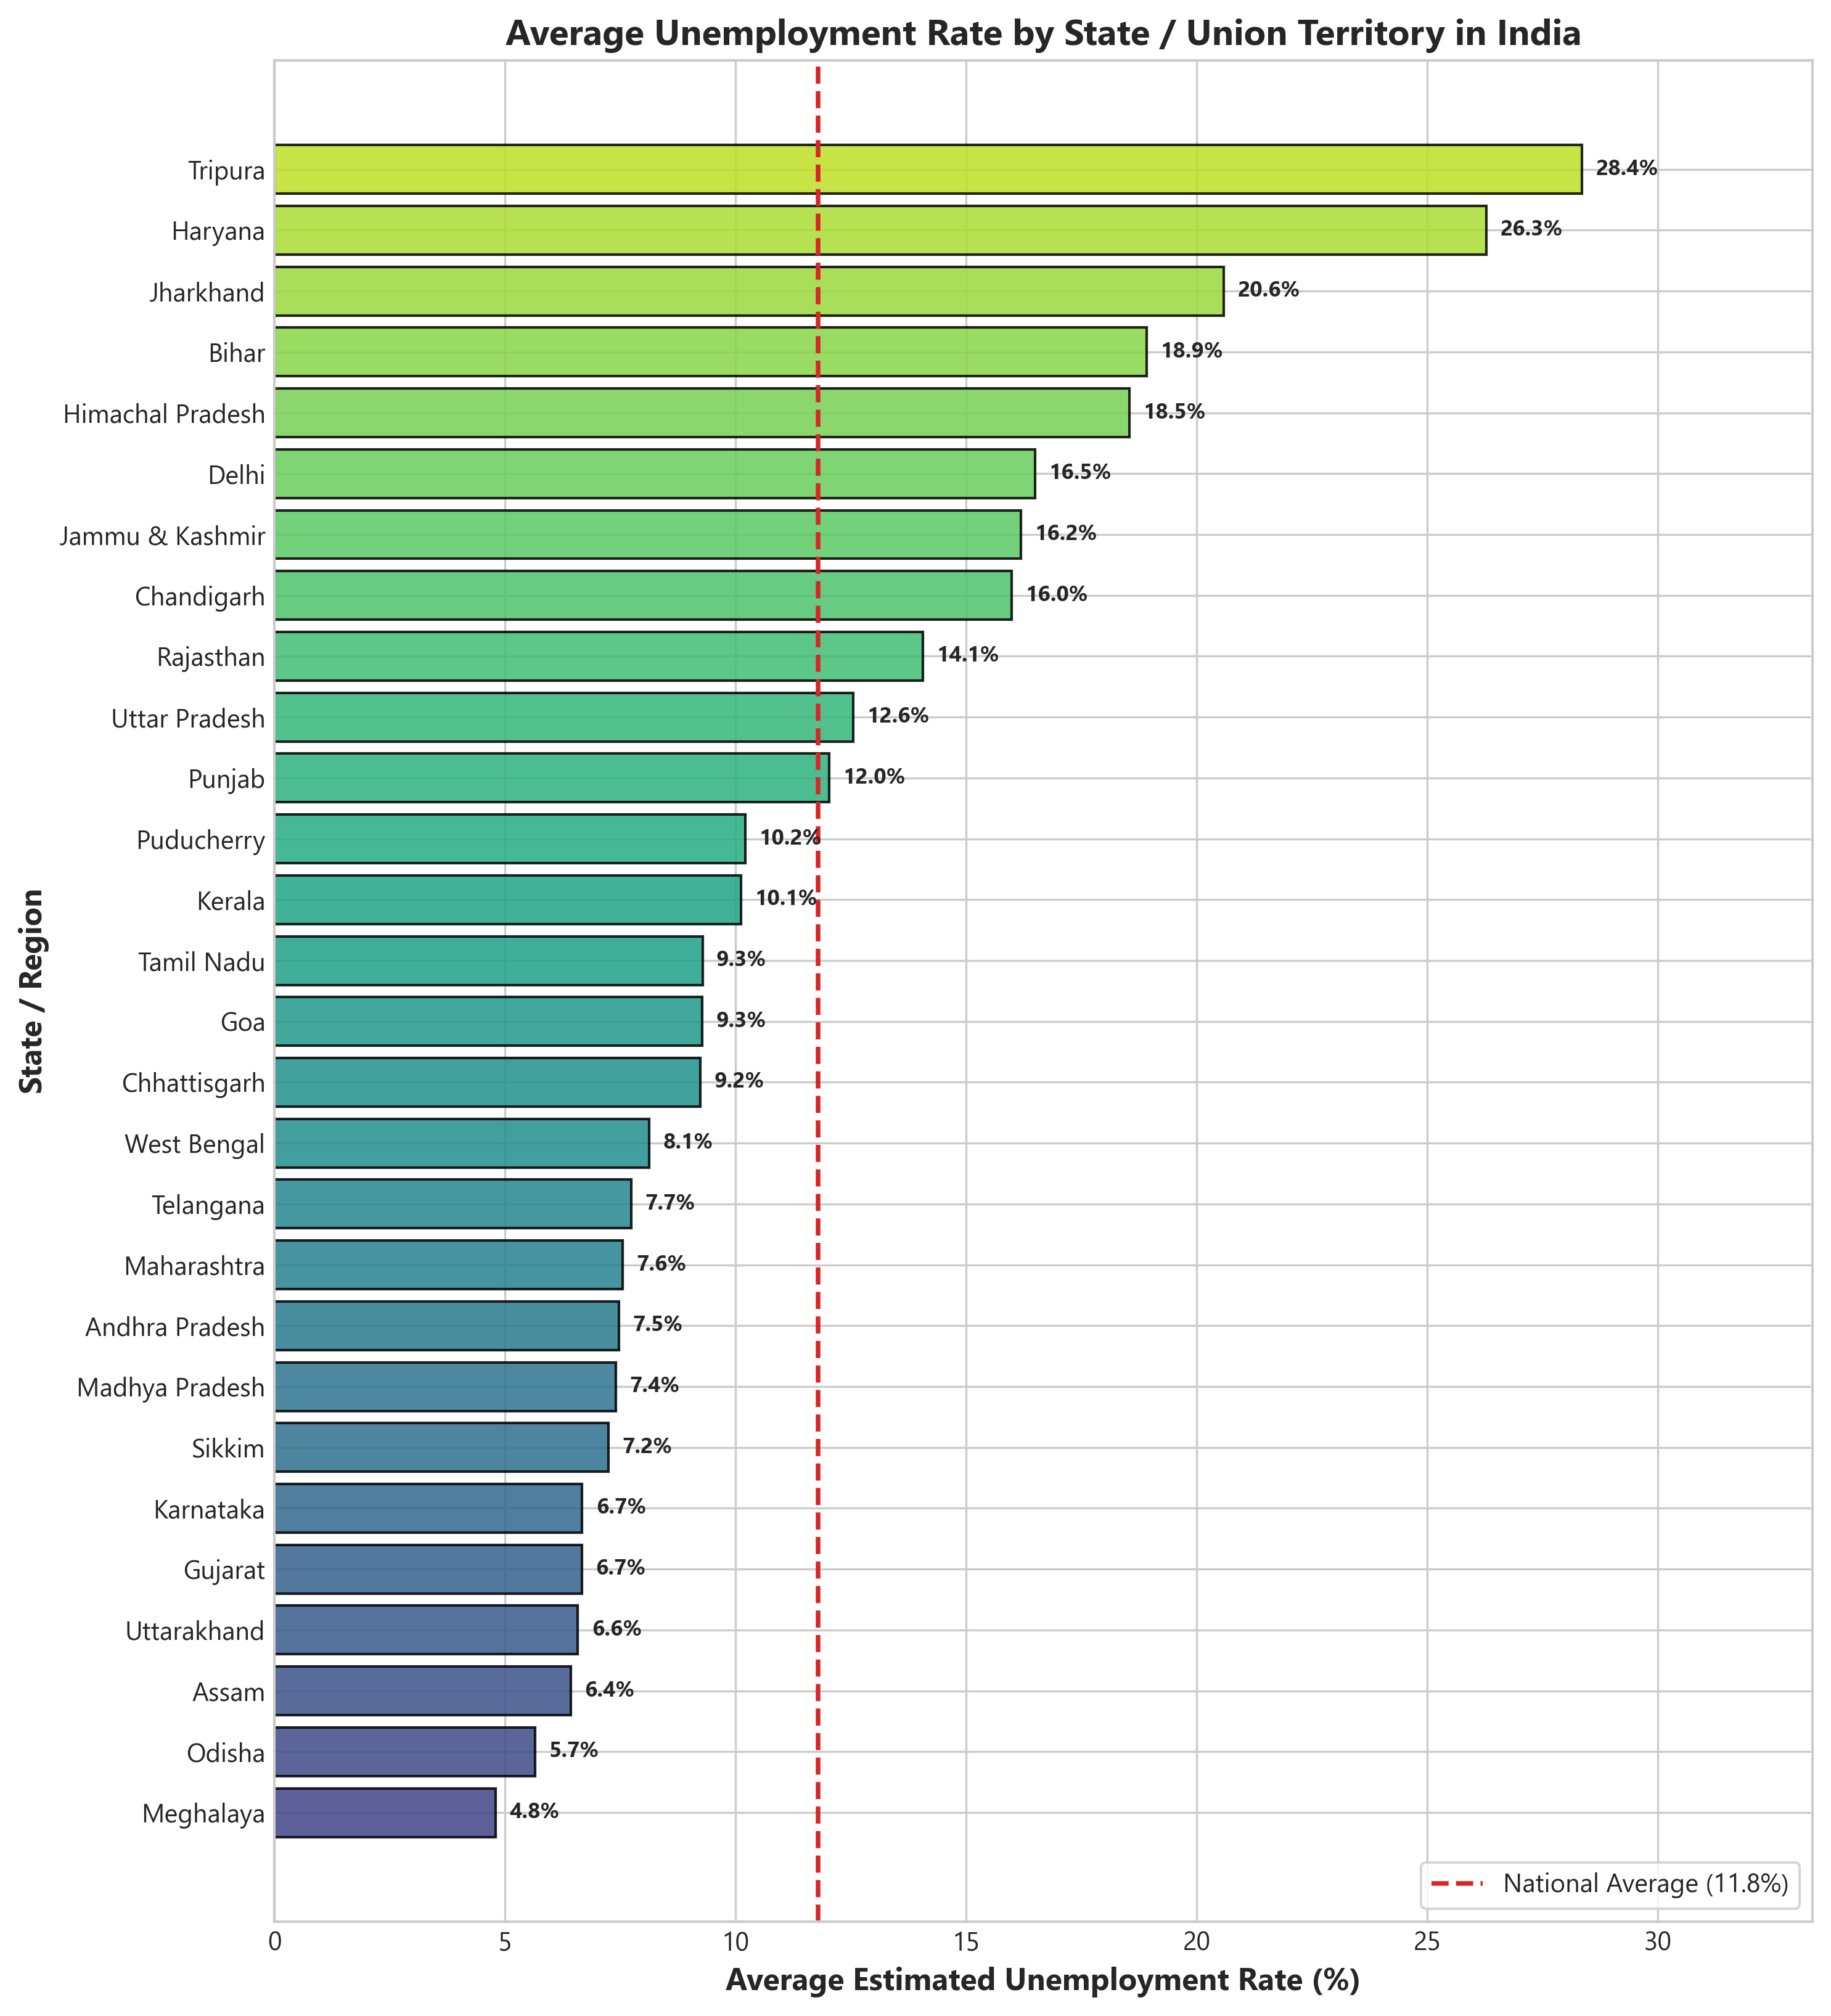

In [7]:
fig2 = plot_regional_comparison(df, save=True)
plt.show()

### 7. Rate Distribution & Area Disparity (Rural vs Urban)

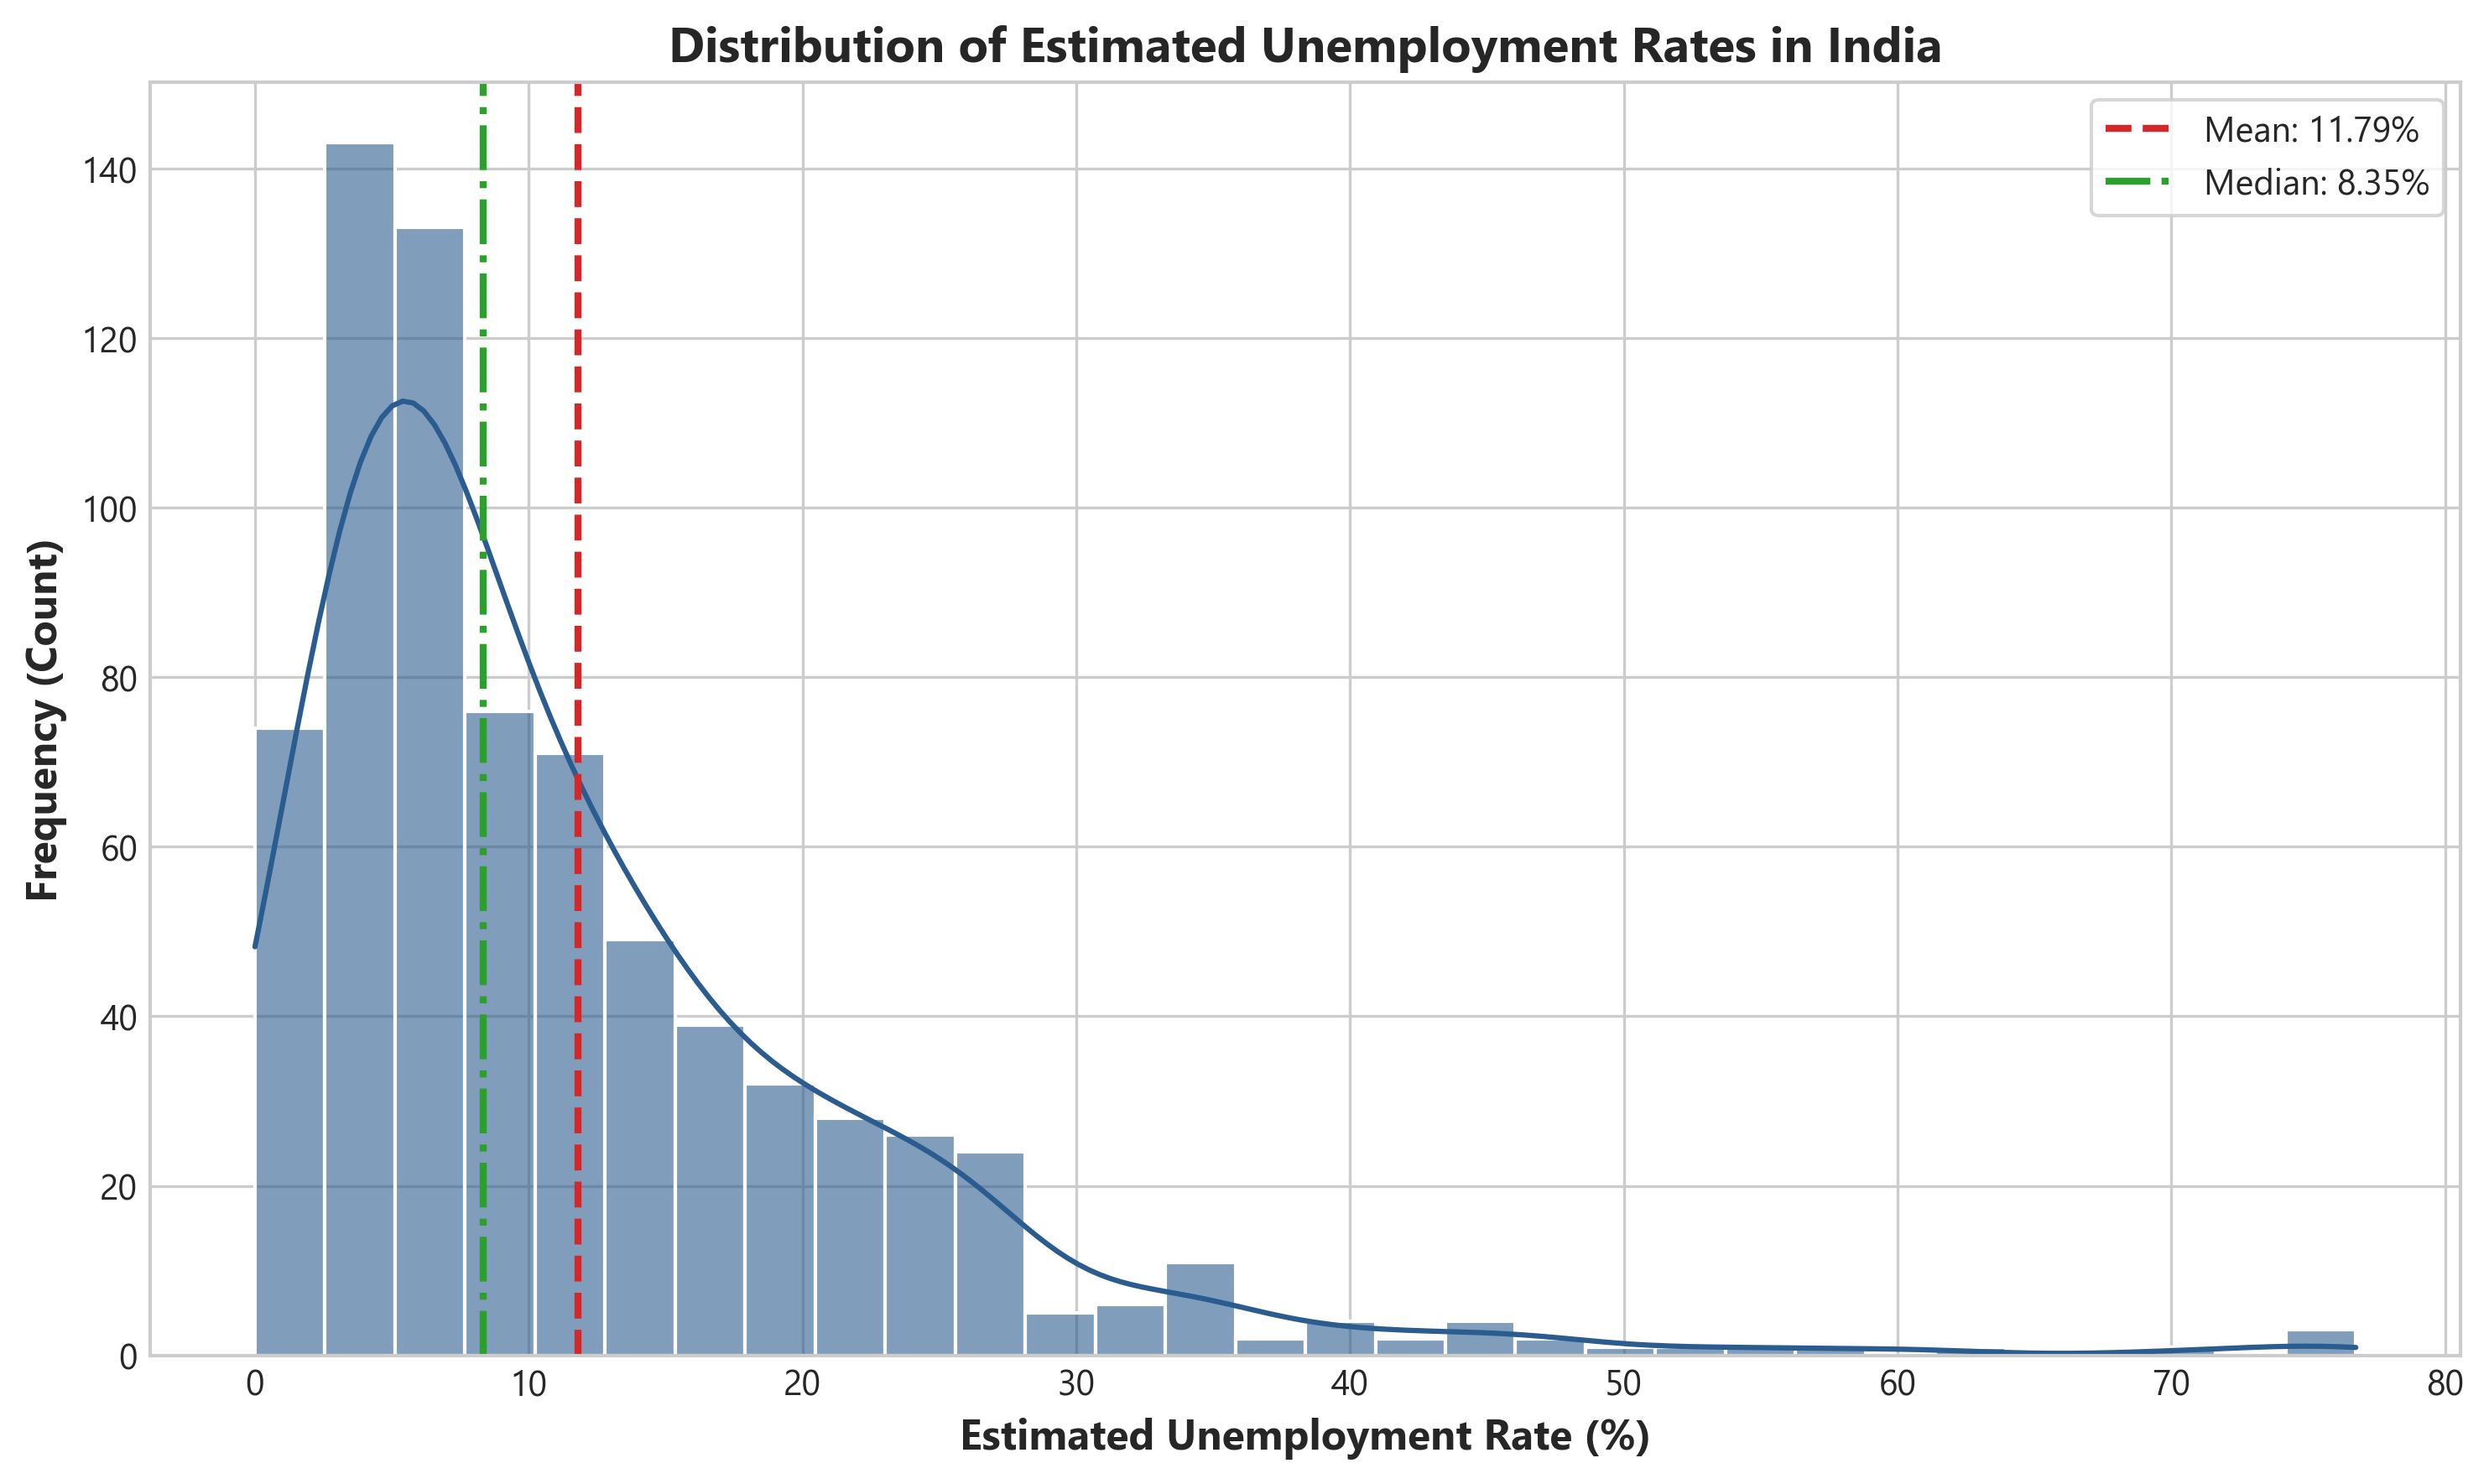

In [8]:
fig3 = plot_distribution(df, save=True)
plt.show()

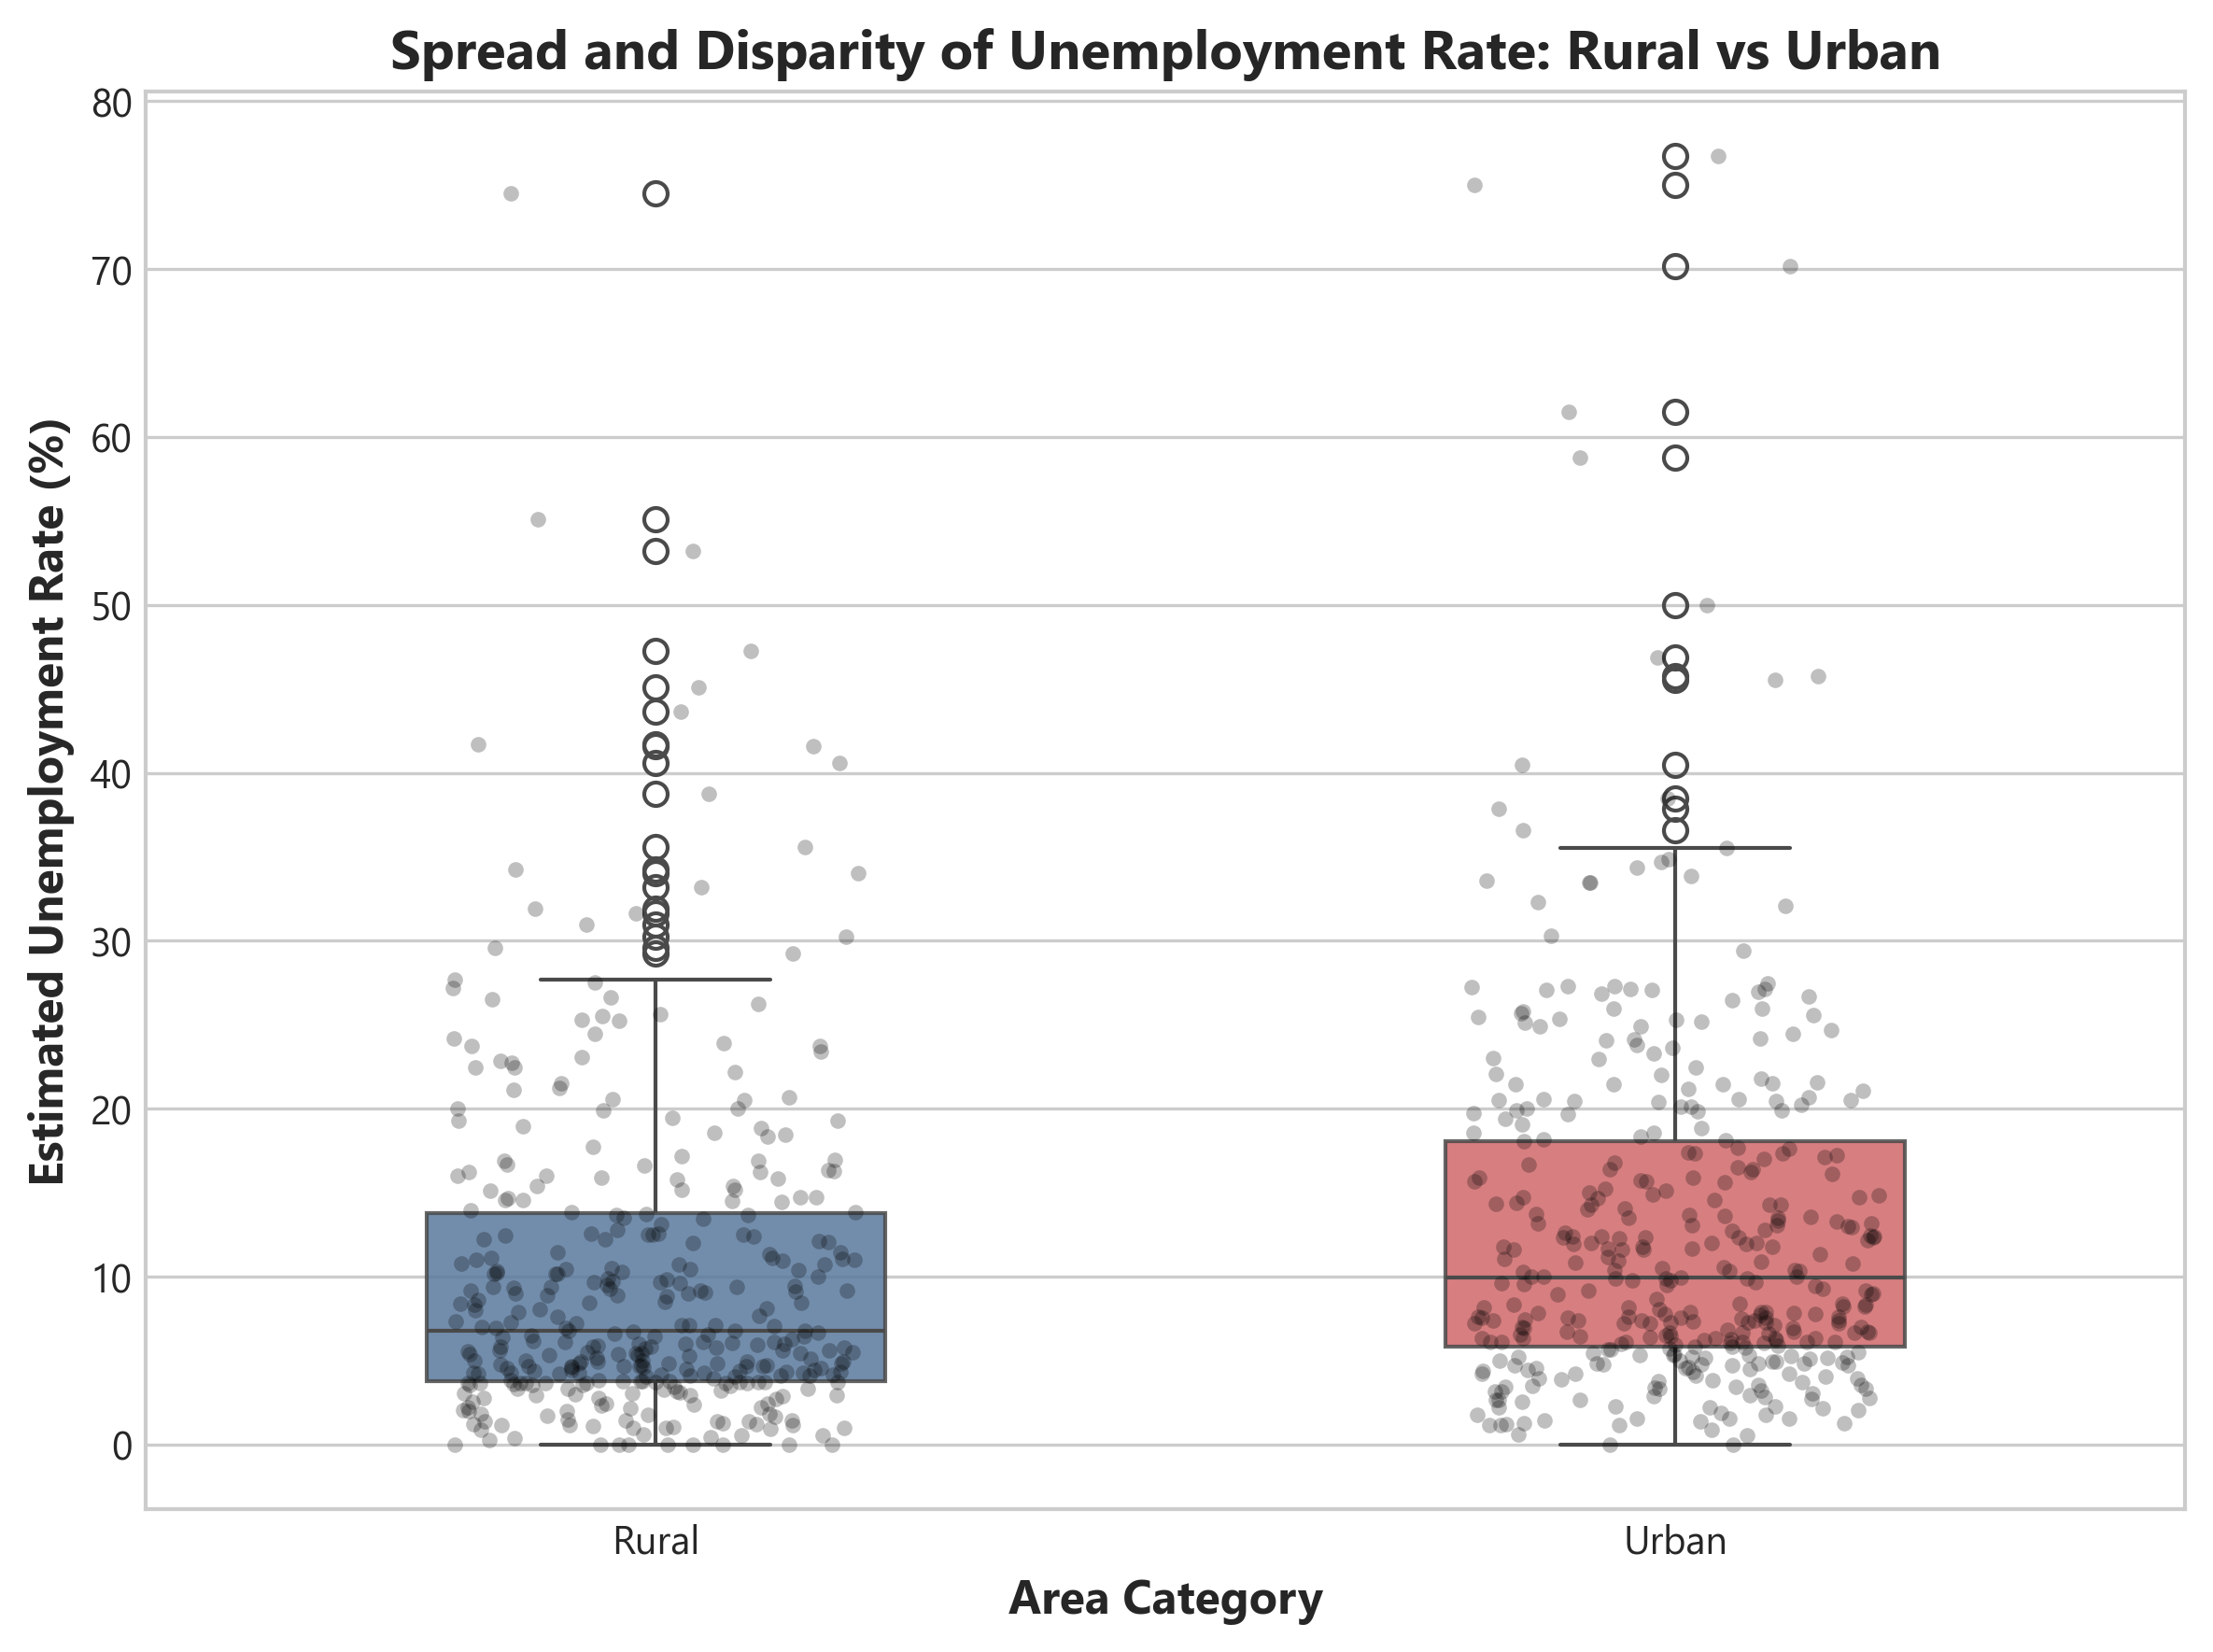

In [9]:
area_df = analyze_area_differences(df)
display(area_df)

fig4 = plot_area_boxplot(df, save=True)
plt.show()

### 8. COVID-19 Pandemic Impact Analysis
Comparing unemployment rate metrics before the pandemic (May 2019 – Feb 2020) and during the COVID-19 lockdown shock (March 2020 – June 2020).

> **Analytical Note:** Changes observed during 2020 coincide with COVID-19 containment measures, but observational data does not prove sole causation due to concurring economic variables.

In [10]:
covid_res = analyze_covid_impact(df)
print(f"Pre-COVID Average Rate:      {covid_res['Pre_COVID_Mean']}%")
print(f"COVID-19 Period Average Rate: {covid_res['COVID_Period_Mean']}%")
print(f"Absolute Increase:            +{covid_res['Absolute_Difference']} percentage points")
print(f"Relative Surge:               +{covid_res['Percentage_Change']}%")

Pre-COVID Average Rate:      9.51%
COVID-19 Period Average Rate: 17.77%
Absolute Increase:            +8.26 percentage points
Relative Surge:               +86.91%


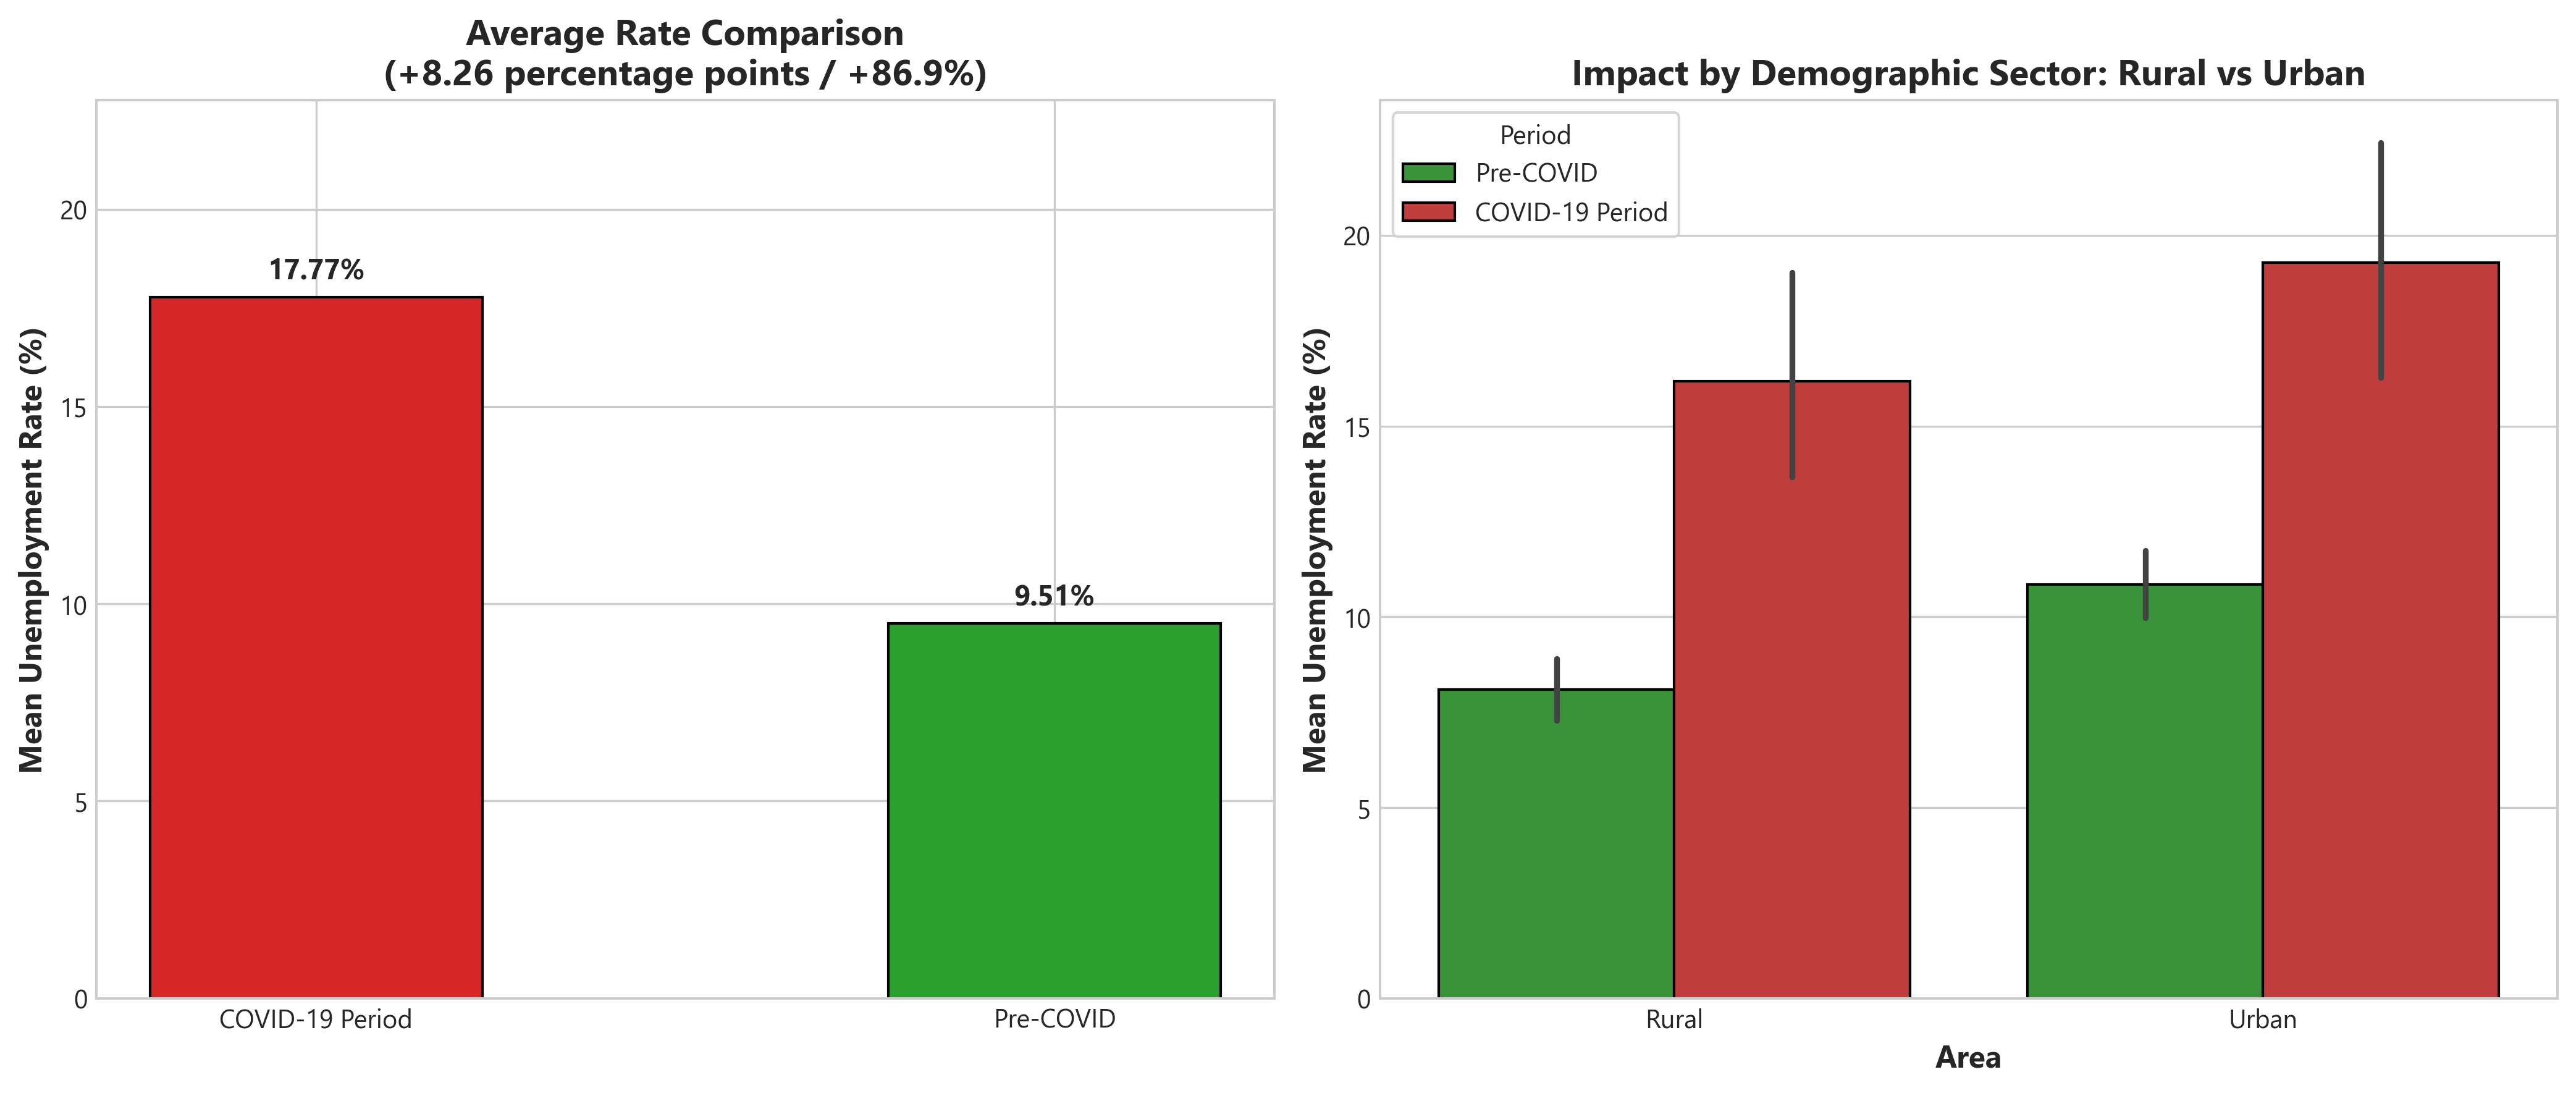

In [11]:
fig5 = plot_covid_comparison(df, save=True)
plt.show()

### 9. Monthly Heatmap of Regional Unemployment

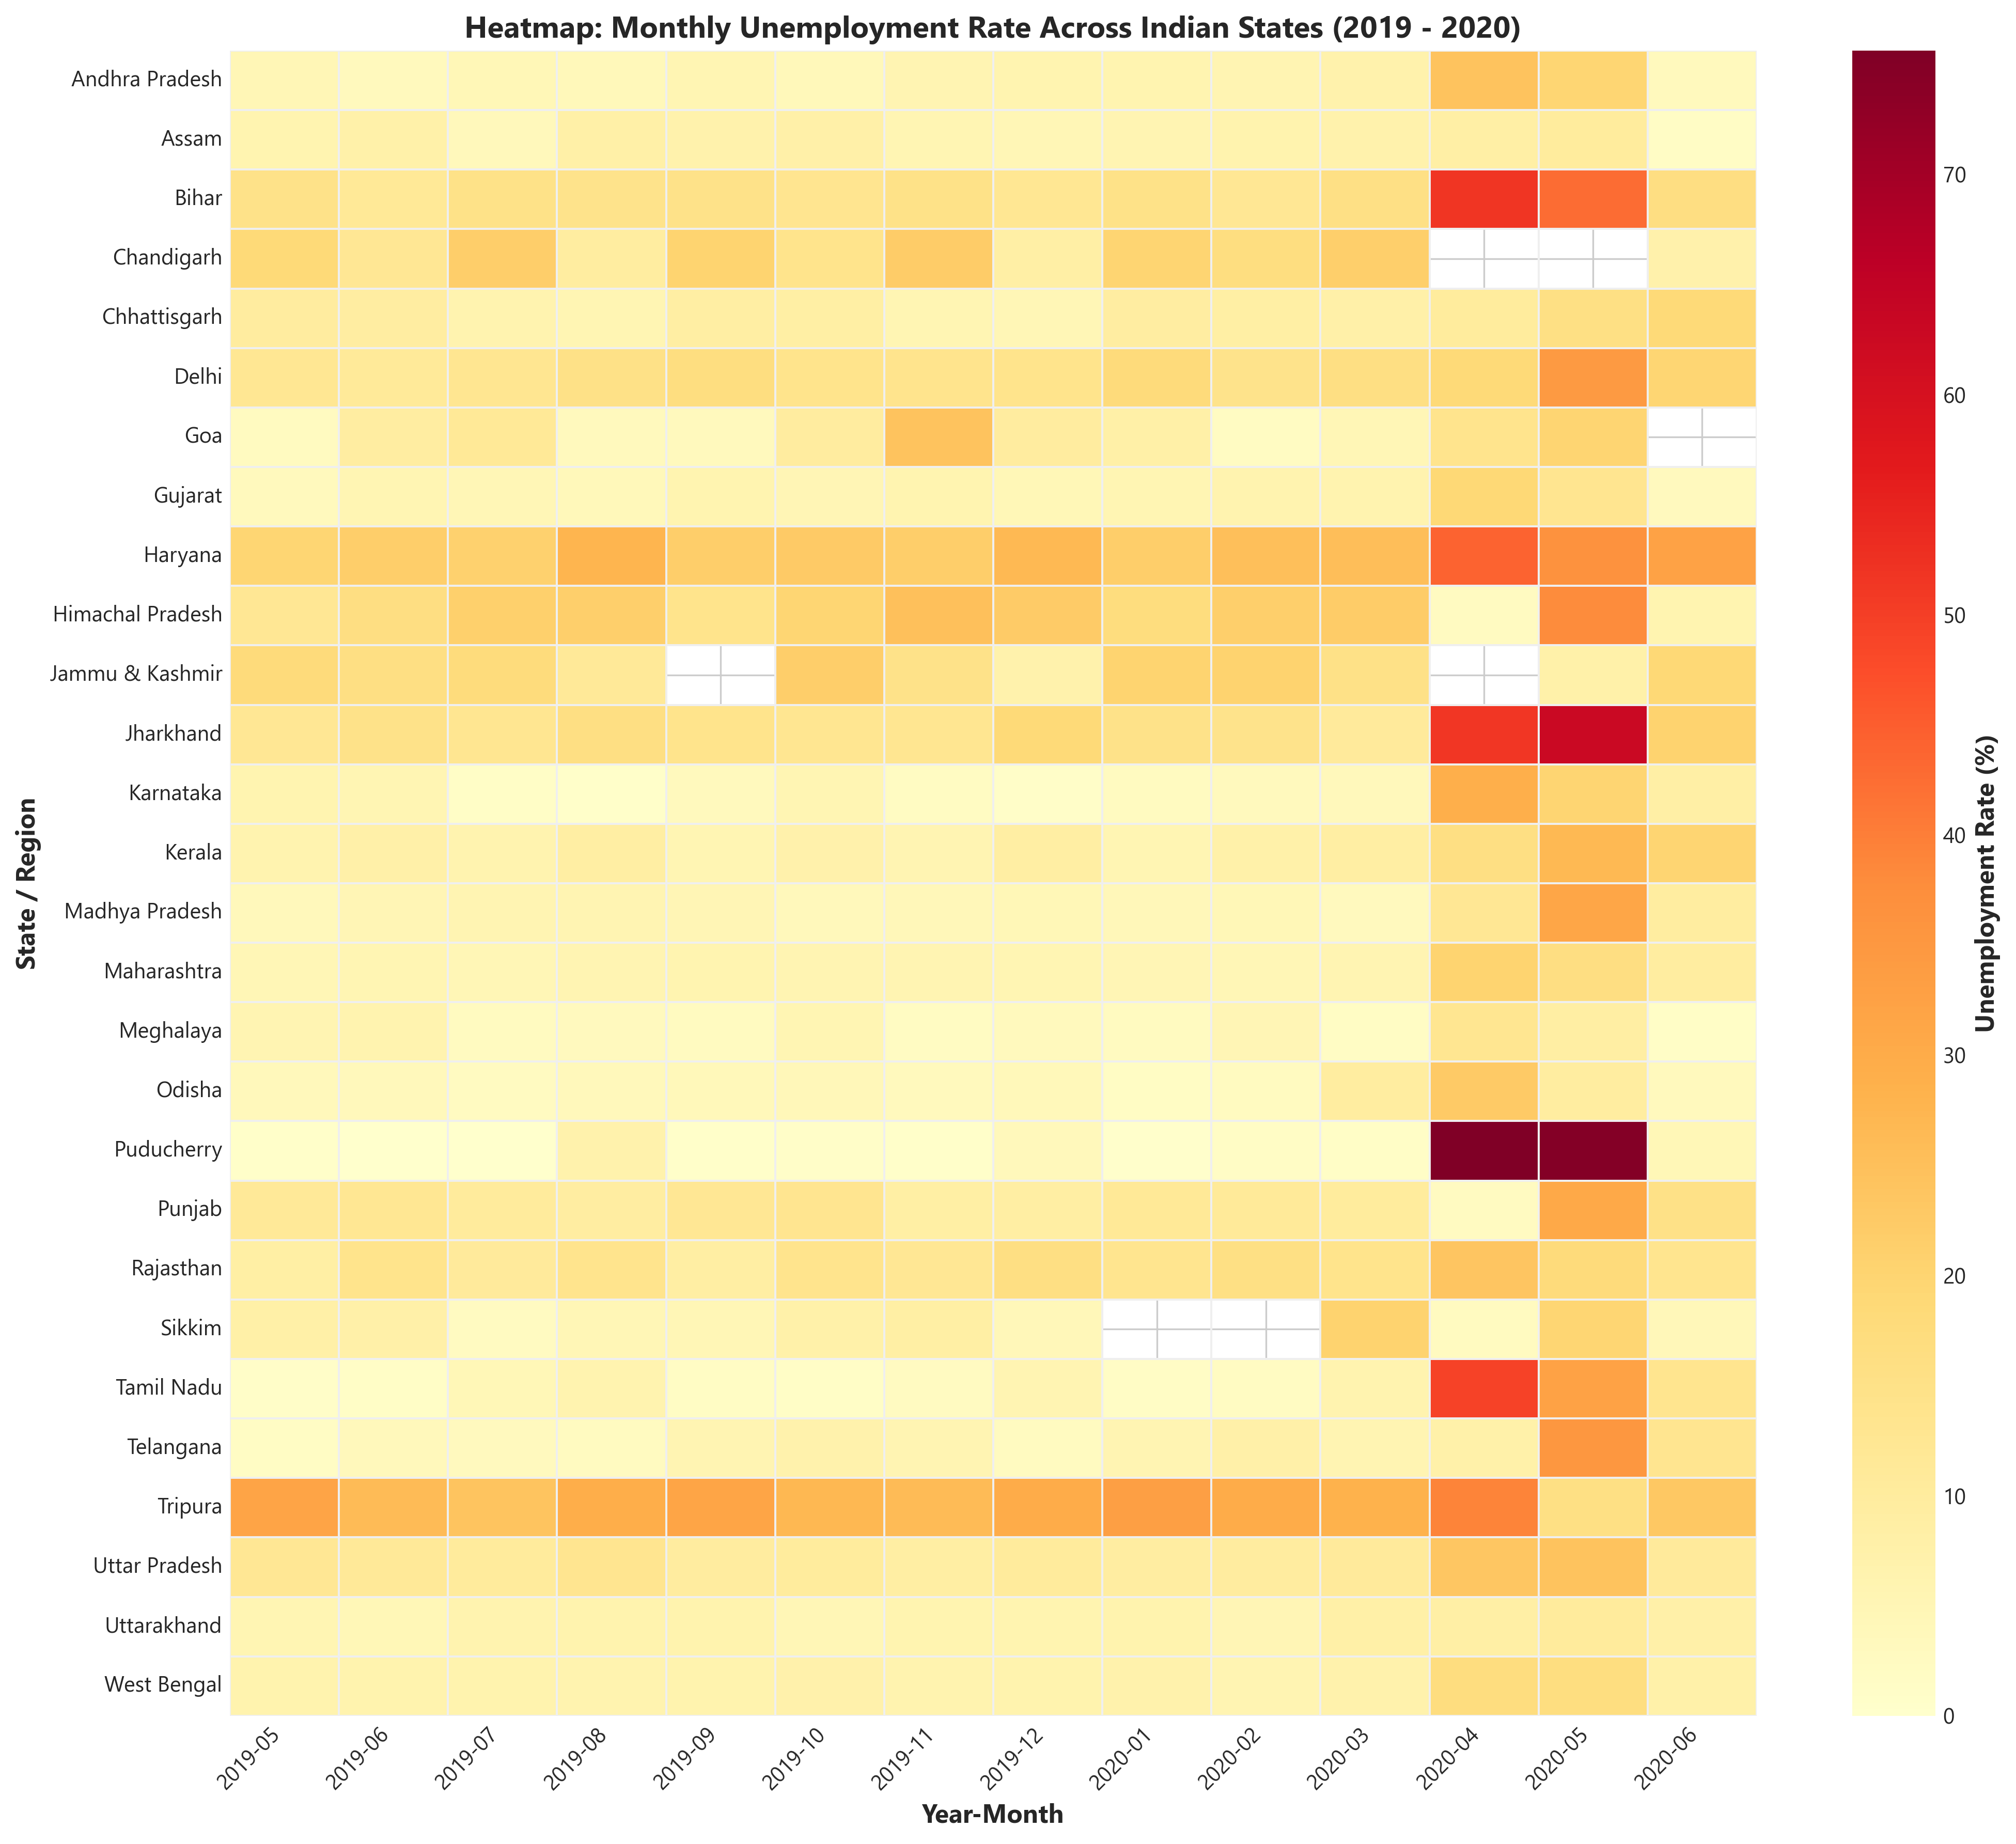

In [12]:
fig6 = plot_monthly_heatmap(df, save=True)
plt.show()

### 10. Key Findings & Policy Insights

In [13]:
findings = generate_key_findings(df, save_findings=True)
print(findings)

CODEALPHA TASK 2: UNEMPLOYMENT ANALYSIS - KEY FINDINGS & INSIGHTS

1. OVERALL NATIONAL UNEMPLOYMENT RATE:
   Across all observations from May 2019 to June 2020, the national average unemployment rate stood at 11.79%, with a median of 8.35%.

2. HIGHEST AND LOWEST RECORDED SINGLE RATES:
   - Peak single observation: 76.74% in Puducherry (Urban) during April 2020.
   - Minimum single observation: 0.00% in Puducherry during May 2019.

3. PEAK MONTHLY NATIONAL SHOCK (COVID-19 LOCKDOWN):
   - The national average unemployment rate spiked to its highest monthly level in May 2020 at 24.88%.
   - In contrast, the lowest monthly national average was recorded in May 2019 at 8.87%.

4. COVID-19 IMPACT (PRE-COVID VS COVID-19 PERIOD):
   - Pre-COVID Average (May 2019 - Feb 2020): 9.51%
   - COVID-19 Period Average (Mar 2020 - Jun 2020): 17.77%
   - Absolute Increase: +8.26 percentage points
   - Relative Surge: +86.91% increase in average unemployment rate.

5. URBAN VS RURAL DISPARITY:
   - Urban 